In [11]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot
from prepare_aging import prepare_data_free as prepare_data

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar

import torch

if torch.cuda.is_available():
    from objective_free_cuda import solve_UV_all_slices_torch as solve_UV_all_slices
else:
    from objective_free import solve_UV_all_slices


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
data_dir = "../../../Data/Aging"
adata_all,  timepoints = prepare_data(data_dir=data_dir)

In [ ]:
seed = 0
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

U, V, pi, aux = solve_UV_all_slices(
                        adata_all, r=50,
                        lam=1e2, mu=1e1, 
                        verbose=False,
                        ot_solver='low_rank',
                        alpha = 0.5,
                        k=100, 
                        sparsify = True,
                    )

In [45]:
# import pickle

# with open("aging_joint_pi.pkl", "rb") as f:
#     pi = pickle.load(f)

# with open("aging_joint_U.pkl", "rb") as f:
#     U = pickle.load(f)

# with open("aging_joint_V.pkl", "rb") as f:
#     V = pickle.load(f)
    
import anndata as ad
import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_all),
            celltype_key="celltype",
            embedding_key="spatial",
            clustering="leiden",
            plot=False, 
            auto_resolution=True,
) 

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_all])
for i, adt in enumerate(adata_all):
    adt.obs['pred_label_matchk'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

# print('ari='+str(ari))
# print('nmi='+str(nmi))


ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_all),
            celltype_key="celltype",
            embedding_key="spatial",
            clustering="leiden",
            plot=False, 
            auto_resolution=False,
) 

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_all])
for i, adt in enumerate(adata_all):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

# print('ari='+str(ari))
# print('nmi='+str(nmi))

adata_cat = ad.concat(adata_all)
# adata_cat.obs.to_csv('result_cells_ref.csv')

clustering at resolution=0.01 has been done! Found 2 clusters.
clustering at resolution=1.2 has been done! Found 34 clusters.
clustering at resolution=0.605 has been done! Found 20 clusters.
clustering at resolution=0.3075 has been done! Found 15 clusters.
clustering at resolution=0.45625 has been done! Found 17 clusters.
clustering at resolution=0.530625 has been done! Found 19 clusters.
clustering at resolution=0.4934375 has been done! Found 18 clusters.
Leiden: target_k=18, best_resolution=0.493, n_clusters=18
clustering at resolution=1.0 has been done! Found 25 clusters.
Leiden: resolution=1.000, n_clusters=25


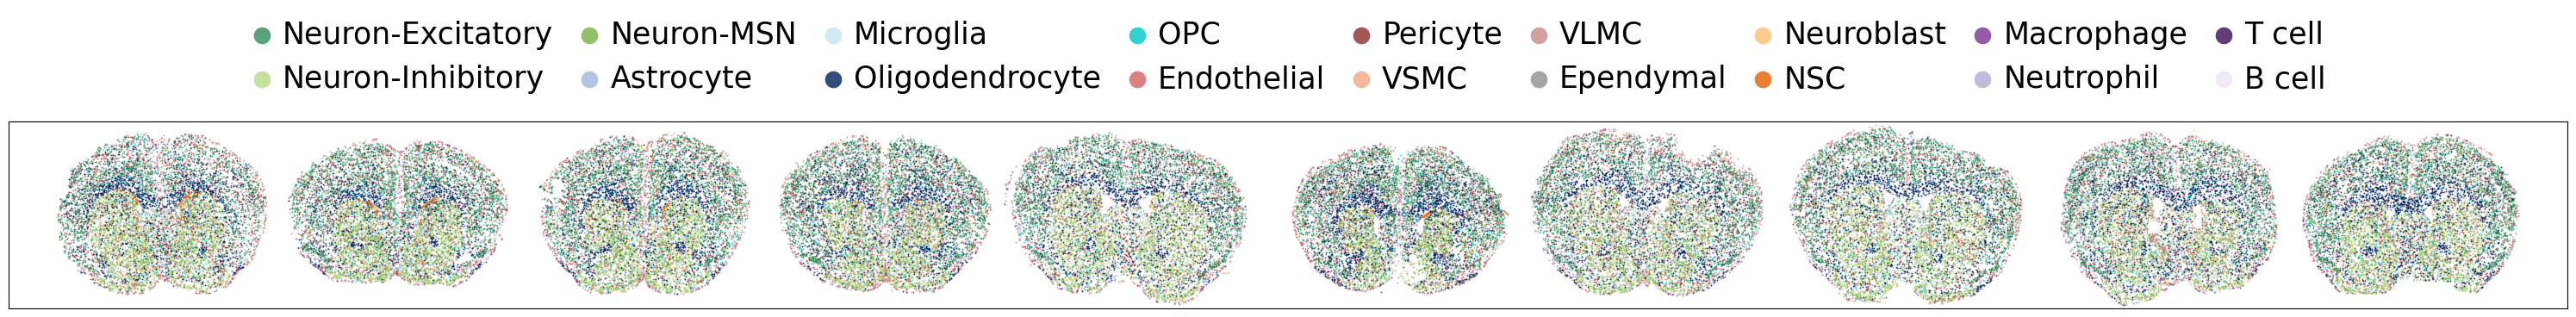

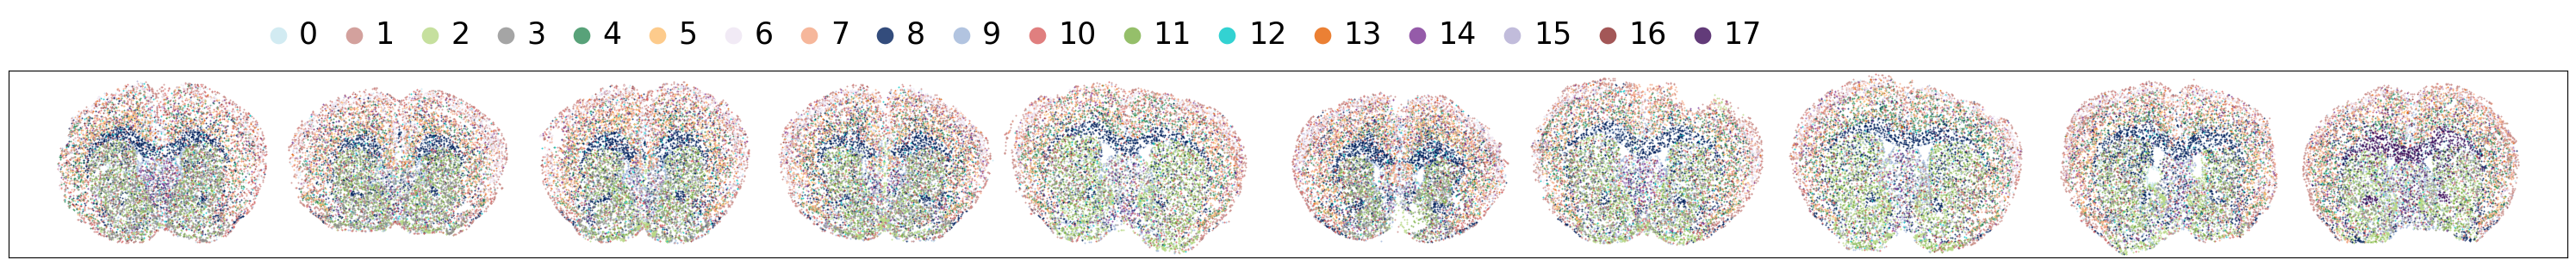

In [5]:


import matplotlib.colors as mcolors
cell_type_colors = {
    # Neurons — keep layer / anatomical structure visible
    "Neuron-Excitatory": "#2E8B57",  # medium green
    "Neuron-Inhibitory": "#B8D986",  # pale yellow-green
    "Neuron-MSN":        "#7BAF45",  # olive green for striatum

    # Glia — Oligo/OPC emphasized
    "Astrocyte":         "#9FB6D9",  # muted pale blue
    "Microglia":         "#C7E7EF",  # very pale cyan
    "Oligodendrocyte":   "#001F5B",
    "OPC":               "#00C7C7",  # bright teal

    # Vasculature — visible but less dominant
    "Endothelial":       "#D95F5F",
    "Pericyte":          "#8C2D2D",
    "VSMC":              "#F4A582",
    "VLMC":              "#C98A85",

    # Other structural
    "Ependymal":         "#8F8F8F",

    # Neurogenic — orange but not too loud
    "Neuroblast":        "#FDBF6F",
    "NSC":               "#E66101",

    # Immune — push into background except macrophage
    "Macrophage":        "#7B3294",
    "Neutrophil":        "#B2ABD2",
    "T cell":            "#3B0A57",#"#D8C6E6",
    "B cell":            "#EEE5F3",
}

cell_types = list(cell_type_colors.keys())
colors_18  = list(cell_type_colors.values())
cmap = mcolors.ListedColormap(colors_18, name="brain_celltypes")

for t in range(len(adata_all)):
    adata_all[t].obs['x'], adata_all[t].obs['y'] = adata_all[t].obsm['spatial'][:,0], adata_all[t].obsm['spatial'][:,1]

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[1::2],
    obs_key="celltype",
    obsm_key="spatial",         
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend_loc='upper center',
    legend_bbox=(0.5,0.9),
    legend_ncol = 9,
    legend_font=25,
    truth_key="celltype",
    truth_cmap=cmap,
    legend_markerscale=10,
    # highlight_labels=['Oligodendrocyte','OPC']
)
plt.show()

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[1::2],
    obs_key="pred_label_matchk",
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend=True,
    legend_bbox=(0.1,0.75),
    legend_ncol = 22,
    legend_font=25,
    truth_key="celltype",
    truth_cmap=cmap,
    legend_markerscale=10,
)
plt.show()

In [17]:
# import pickle
# with open("aging_joint_U.pkl", "wb") as f:
#     pickle.dump(U, f, protocol=pickle.HIGHEST_PROTOCOL)

# with open("aging_joint_V.pkl", "wb") as f:
#     pickle.dump(V, f, protocol=pickle.HIGHEST_PROTOCOL)

# with open("aging_joint_pi.pkl", "wb") as f:
#     pickle.dump(pi, f, protocol=pickle.HIGHEST_PROTOCOL)

In [8]:
from plot_utils import plot_V_dotplot_from_adata
from downstream import region_de_wilcoxon, clean_gene_for_enrichr, plot_gene_lollipop_by_region
from downstream import make_gene_name_table, add_parsed_gene_names_to_de

In [44]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu


def marker_enrichment_test(
    W,
    genes,
    marker_genes,
    alternative="greater",   # marker > background
    normalize_rows=False,    # NEW: row-normalize |W| to test specificity, not magnitude
    warn_missing=True,       # NEW: report markers absent from `genes`
    min_markers=1,           # NEW: floor on matched markers
    return_missing=False,    # NEW: also return the set of unmatched markers
):
    """
    Test if |weights| of marker genes are larger than non-markers
    for each basis vector.

    Returns a DataFrame with p-values and effect sizes.
    """
    W = np.asarray(W)
    genes = pd.Index([g.upper() for g in genes])
    marker_genes = [g.upper() for g in marker_genes]

    marker_idx = [i for i, g in enumerate(genes) if g in marker_genes]
    non_marker_idx = [i for i in range(len(genes)) if i not in marker_idx]

    missing = sorted(set(marker_genes) - set(genes[marker_idx]))
    if warn_missing and missing:
        print(f"warning: {len(missing)} markers not found: {missing}")

    if len(marker_idx) == 0:
        raise ValueError("No markers matched.")
    if len(marker_idx) < min_markers:
        raise ValueError(
            f"only {len(marker_idx)} markers matched, need >= {min_markers}"
        )

    V = np.abs(W)
    if normalize_rows:
        V = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-12)

    results = []

    for j in range(V.shape[1]):
        v = V[:, j]

        marker_vals = v[marker_idx]
        background_vals = v[non_marker_idx]

        stat, pval = mannwhitneyu(
            marker_vals,
            background_vals,
            alternative=alternative
        )

        # Effect size: difference in means
        effect = marker_vals.mean() - background_vals.mean()

        results.append({
            "basis_index": j,
            "p_value": pval,
            "effect_size": effect,
            "marker_mean": marker_vals.mean(),
            "background_mean": background_vals.mean(),
            # NEW
            "auc": stat / (len(marker_vals) * len(background_vals)),
            "fold": marker_vals.mean() / (background_vals.mean() + 1e-12),
            "marker_median": np.median(marker_vals),
            "background_median": np.median(background_vals),
            "n_markers": len(marker_vals),
            "frac_marker_nonzero": float((marker_vals > 0).mean()),
            "frac_background_nonzero": float((background_vals > 0).mean()),
        })

    df = pd.DataFrame(results)

    # Multiple testing correction (Benjamini–Hochberg)
    df = df.sort_values("p_value")
    m = len(df)
    df["rank"] = np.arange(1, m + 1)
    df["q_value"] = df["p_value"] * m / df["rank"]
    df["q_value"] = np.minimum.accumulate(df["q_value"][::-1])[::-1]

    df = df.sort_values("q_value")
    return (df, missing) if return_missing else df
    

opc_markers   = ["Pdgfra",  "Ptprz1", "Vcan", "Olig2", "Gpr17"]
# cop_markers   = ["Gpr17", "Bmp4", "Neu4", "Enpp6", "Itpr2", "Tcf7l2"]
oligo_markers = ["Mog", "Cldn11", "Opalin", "Klk6", "Apod"]

df = marker_enrichment_test(U, adata_all[0].var_names  ,  opc_markers)

print(df.head())



df = marker_enrichment_test(U, adata_all[0].var_names  ,  oligo_markers)

print(df.head())

    basis_index       p_value  effect_size  marker_mean  background_mean  \
21           21  4.146582e-07     0.160779     0.168022         0.007244   
49           49  8.461616e-06     0.340075     0.346459         0.006384   
46           46  7.191778e-05     0.156479     0.169079         0.012599   
23           23  4.308949e-03     0.012812     0.023509         0.010697   
48           48  9.609391e-02    -0.003502     0.002689         0.006190   

         auc       fold  marker_median  background_median  n_markers  \
21  0.971525  23.196291       0.057704                0.0          5   
49  0.995932  54.273342       0.260847                0.0          5   
46  0.963390  13.419637       0.064898                0.0          5   
23  0.789492   2.197659       0.013611                0.0          5   
48  0.620678   0.434327       0.000000                0.0          5   

    frac_marker_nonzero  frac_background_nonzero  rank   q_value  
21                  1.0                 0.2

/tmp/ipykernel_1810443/2701266588.py:34: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


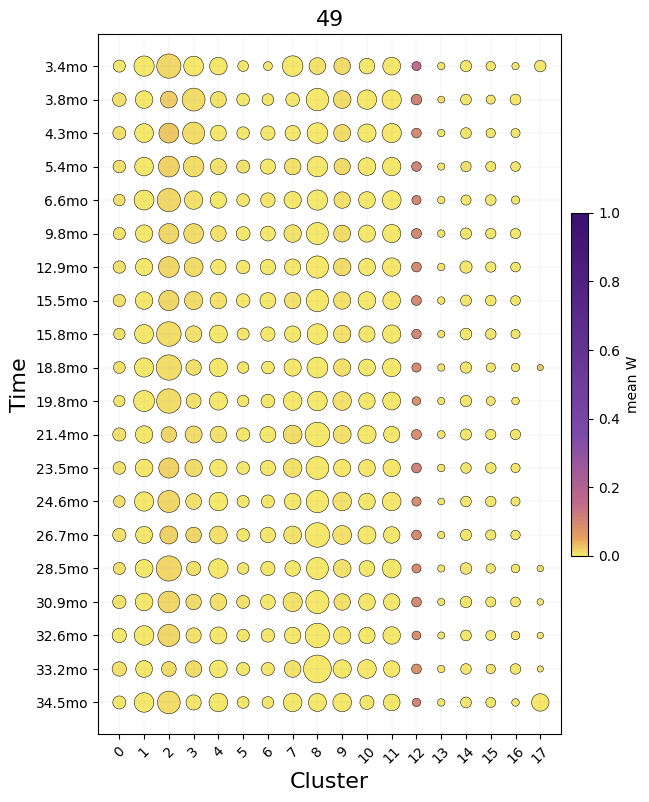

/tmp/ipykernel_1810443/2701266588.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


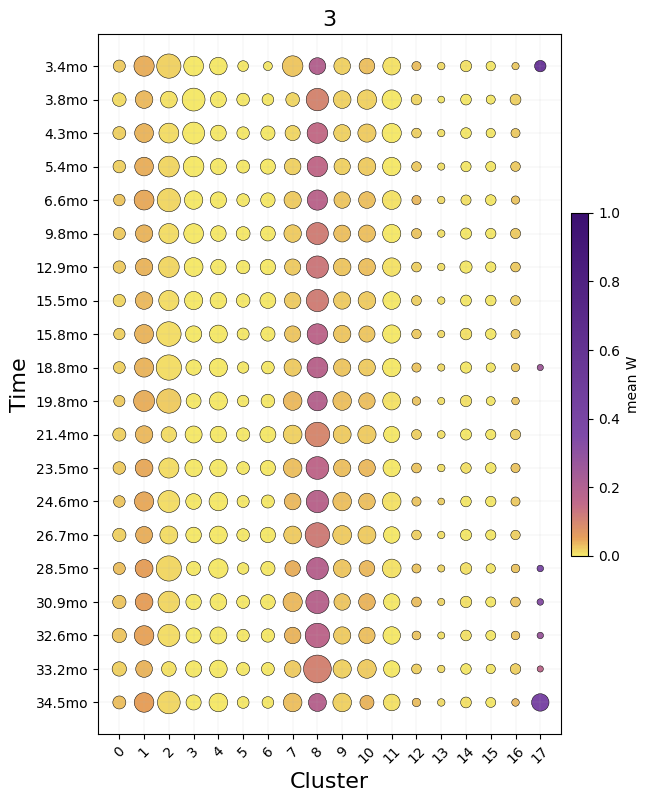

In [43]:

import matplotlib.colors as mcolors

soft_plasma_r = mcolors.LinearSegmentedColormap.from_list(
    "soft_plasma_r",
    [
        (0.00, "#F5E86B"),  # 0: soft yellow
        (0.05, "#E6A15C"),  # very small values already orange
        (0.15, "#C16A8A"),  # low but meaningful values rose
        (0.35, "#7E4AA8"),  # enriched values purple
        (1.00, "#3B0F70"),  # very high values dark purple
    ]
)
times_label = ['3.4mo', '3.8mo', '4.3mo', '5.4mo', '6.6mo',
               '9.8mo', '12.9mo', '15.5mo', '15.8mo', '18.8mo',
               '19.8mo', '21.4mo', '23.5mo', '24.6mo', '26.7mo',
               '28.5mo', '30.9mo', '32.6mo', '33.2mo', '34.5mo']

fig = plt.figure(figsize=(7,10))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])   # [left, bottom, width, height]


fig = plot_V_dotplot_from_adata(
    adata_list=adata_all,
    V_list=[V[i]/np.sum(V[i], axis=1, keepdims=True) for i in range(len(V))],
    celltype= 49,#'Oligodendrocyte precursor cells',
    celltype_names=list(range(50)),
    region_key="pred_label_matchk",
    times=times_label,
    agg="mean",
    cmap=soft_plasma_r,
    ax = ax,
)

plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(7,10))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])   # [left, bottom, width, height]

fig = plot_V_dotplot_from_adata(
    adata_list=adata_all,
    V_list=[V[i]/np.sum(V[i], axis=1, keepdims=True) for i in range(len(V))],
    celltype= 3,#'Oligodendrocyte precursor cells',
    celltype_names=list(range(50)),
    region_key="pred_label_matchk",
    times=times_label,
    agg="mean",
    cmap=soft_plasma_r,
    ax = ax,
)

plt.tight_layout()
plt.show()

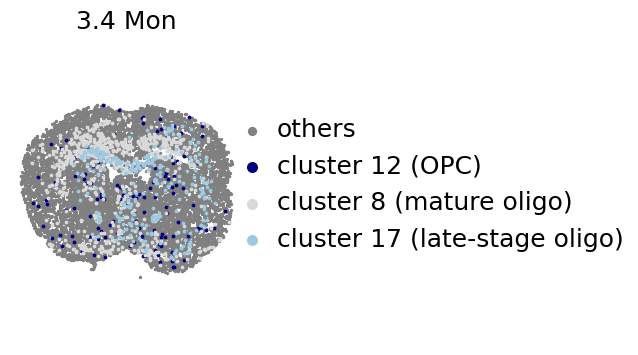

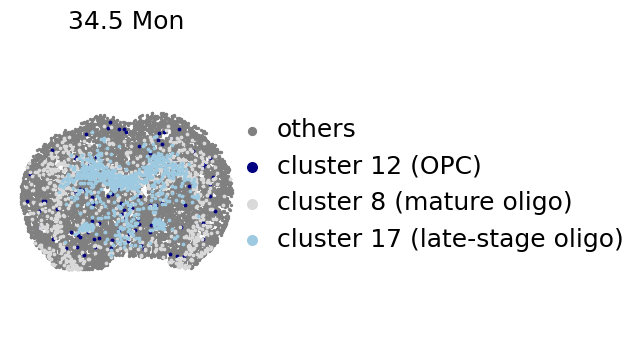

In [37]:
plt.rcParams['figure.figsize'] = (3,4)
cmap = plt.get_cmap("tab20c")
colors = cmap(np.linspace(0, 11/20, 20))

regions_of_interest = [12, 8, 17]#[22, 0, 29]
for t in [0, 19]:
    # adata_all[t].obs['x'], adata_all[t].obs['y'] = adata_all[t].obsm['spatial'][:,0], adata_all[t].obsm['spatial'][:,1]
    plt.scatter(adata_all[t].obs['x'], adata_all[t].obs['y'], c='gray', s=2, label='others')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == 14].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == 14].obs['y'], s=3,  color="#000080",  label='cluster 14')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == 0].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == 0].obs['y'], s=3,  color="#d9d9d9", label='cluster 0')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == 13].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == 13].obs['y'], s=3,  color="#9ecae1",  label='cluster 13')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[0]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[0]].obs['y'], s=3,  color="#000080",  label='cluster 12 (OPC)')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[1]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[1]].obs['y'], s=3,  color="#d9d9d9", label='cluster 8 (mature oligo)')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[2]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[2]].obs['y'], s=3,  color="#9ecae1",  label='cluster 17 (late-stage oligo)')
    

    plt.axis('equal')
    plt.axis('off')
    plt.legend(
        frameon=False,
        fontsize=18,
        markerscale=4,      # makes legend dots larger
        handlelength=1.2,
        handletextpad=0.4,
        borderpad=0.2,
        labelspacing=0.5,
        loc="center left",
        bbox_to_anchor=(0.9, 0.52),
        ncol=1
    )
    plt.title(str(timepoints[t])+' Mon',fontsize=18)
    plt.show()